Loading weights:   0%|          | 0/503 [00:00<?, ?it/s]

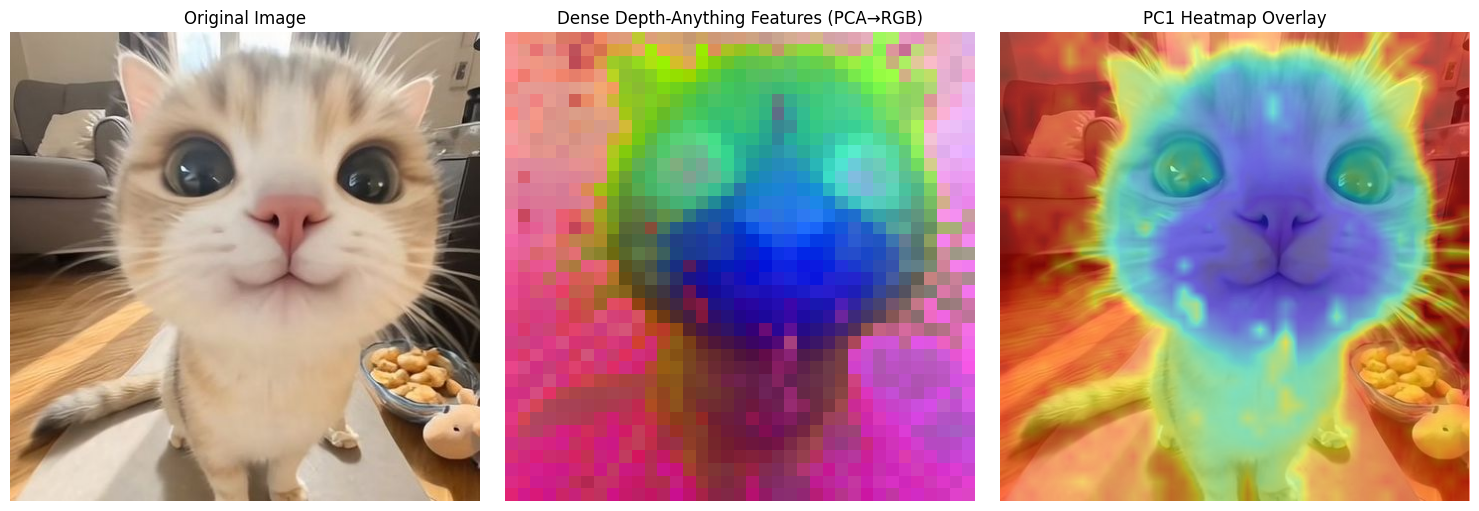

In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import DepthAnythingForDepthEstimation, AutoImageProcessor
from PIL import Image

# --- 1. Extract dense features with Depth Anything ---
model_name = "depth-anything/Depth-Anything-V2-Large-hf"  # <-- FIX: add '-hf'
model = DepthAnythingForDepthEstimation.from_pretrained(model_name).eval()
processor = AutoImageProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    backbone_outputs = model.backbone(inputs["pixel_values"])
    features = backbone_outputs.feature_maps[-1]

    if features.dim() == 3:
        B, N, D = features.shape
        _, _, h, w = inputs["pixel_values"].shape
        patch_size = model.config.patch_size  # 14
        H = h // patch_size
        W = w // patch_size

        # ---------------------------------------------------------
        # FIX: Remove the CLS token (first token), then reshape
        features = features[:, 1:, :]  # (B, H*W, D)
        # ---------------------------------------------------------

        features = features.reshape(B, H, W, D).permute(0, 3, 1, 2)

    B, D, H, W = features.shape
    grid_h, grid_w = H, W

    features = features.permute(0, 2, 3, 1)
    features_np = features[0].reshape(-1, D).numpy()

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(features_np)

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(grid_h, grid_w, 3)

# --- 3. Plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense Depth-Anything Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(grid_h, grid_w)
axes[2].imshow(image)
axes[2].imshow(
    pca1,
    cmap="jet",
    alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("depth_anything_dense_features.png", dpi=150)
plt.show()